> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage4_agent_and_mcp_execution_ko.ipynb`)](../ko/stage4_agent_and_mcp_execution_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Methodology Guide](../../methodology/en/04_stage4_agent_and_mcp_en.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage4)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → **[▶ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb)** → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 4. [Build Agent & Answer] 8-Tool Modular MCP Server, Slot Validation & 2-Pass AI FDE Agent Execution
## Step 4.1 8 MCP Tools & 2-Pass Agent Architecture Setup · Step 4.2 Deterministic Penalty Simulation & Guardrailed Answering

Stage 4 implements **Phase 6 (Agent & MCP Setup)** and **Phase 7 (Grounded Answering)**. To prevent LLM math errors or entity hallucinations, we combine **(1) Live BigQuery Catalog Slot Validation (`resolve_params`)**, **(2) the 8-Tool Modular MCP Server (`DomainMcpServer`) executing deterministic SQL and parameterized ISO GQL**, and **(3) the 4-Step, 2-Pass Gemini (`gemini-3.8-flash`) Reasoning Engine (`AiFdeAgentEngine`)**, verifying both `GROUNDED` answers and boundary guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`).

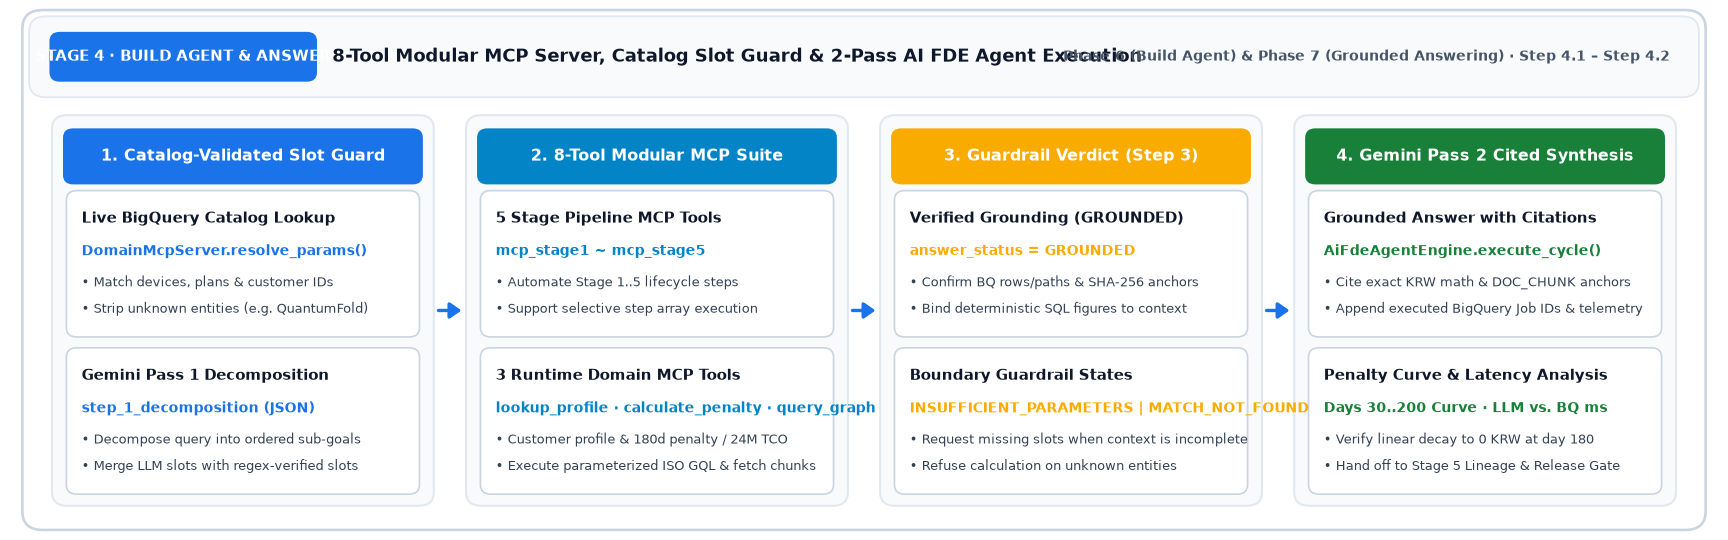


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: Agent & MCP Architecture Setup] 2-Pass Orchestration Blueprint, 8-Tool MCP Catalog & `mcp_stage4_agent_orchestration`


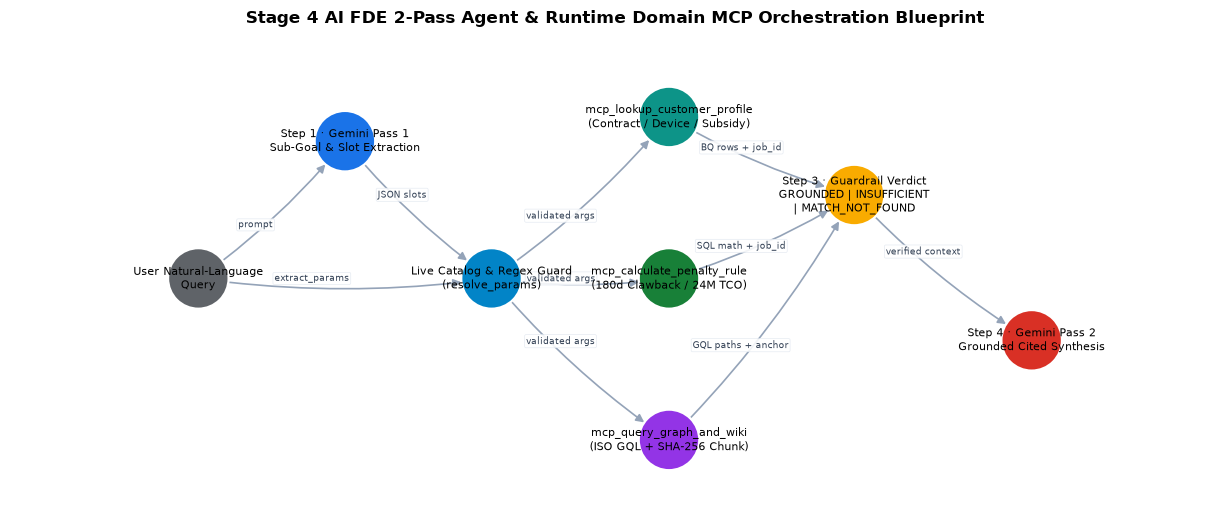

,name,stage,category,steps,spec_origin,description_en
0,mcp_stage1_asset_discovery,STAGE 1,stage_pipeline,"[profile_tables, scan_guides, prune_noise, tag_pii_governance]",GCP_NATIVE,Stage 1 live BigQuery table profiling and customer ID de-identification check
1,mcp_stage2_wiki_and_semantic,STAGE 2,stage_pipeline,"[compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges]",CUSTOM_EXTENSION,Stage 2 GCS wiki object listing and BigQuery chunk/rule anchor lookup
2,mcp_stage3_property_graph,STAGE 3,stage_pipeline,"[promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates]",GCP_NATIVE,Stage 3 node-table duplicate-key check and Property Graph GQL path count
3,mcp_stage4_agent_orchestration,STAGE 4,stage_pipeline,"[decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors]",CUSTOM_EXTENSION,Stage 4 domain rules and grounding chunks used by the agent (BigQuery)
4,mcp_stage5_lineage_and_eval,STAGE 5,stage_pipeline,"[build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures]",CUSTOM_EXTENSION,Stage 5 contract→device/plan/subsidy→rule→chunk lineage join and latest validation sum...
5,mcp_lookup_customer_profile,RUNTIME,runtime_domain,"[lookup_contract, lookup_device_price, lookup_subsidy_policy]",CUSTOM_EXTENSION,"Customer contract, device price and subsidy lookup (returns 0 rows + live catalog on m..."
6,mcp_calculate_penalty_rule,RUNTIME,runtime_domain,"[check_exemptions, compute_180d_prorated_clawback, compare_24m_tco]",CUSTOM_EXTENSION,"180-day prorated penalty, exemption and 24-month TCO computed in BigQuery SQL"
7,mcp_query_graph_and_wiki,RUNTIME,runtime_domain,"[traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema]",GCP_NATIVE,Property Graph GRAPH_TABLE multi-hop traversal and grounding chunk retrieval


**`mcp_stage4_agent_orchestration`** · status `SUCCESS` · steps `decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors` · BigQuery jobs 1 (449 ms)

Retrieved 4 codified domain rules and grounding chunk anchors

- `job_rWLEFQmDJBti3UzRkAb1w6MsB-Jn`

,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,anchor
0,RULE_SIX_PLAN_180D,"180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,Public Subsidy & Retail Additional Subsidy Cap (15%) Rule,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,anchor_a52e1a72869f
2,RULE_TCO_24M,24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,Senior/Welfare Plan Transition & Military Suspension Penalty Exemption Rule,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,anchor_269d9c42e05c


In [2]:
H.draw_agent_architecture()
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_origin", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("mcp_stage4_agent_orchestration", {"steps": ["decompose_subgoals", "dispatch_domain_mcps", "verify_grounding_anchors"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: Catalog-Validated Slot Resolution (`resolve_params`)] Extracting Parameters & Stripping Unregistered Entities


In [3]:
sample_queries = [
    "If customer CUST_DEMO_001 downgrades to 5G Light (37,000 KRW) on day 120, what is the penalty?",
    "When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the subsidy and net price?",
    "What is the penalty if customer CUST_NOT_EXIST_999 switches to a 99,000 KRW plan on a QuantumFold 99 device?",
    "I just activated my line—what is the penalty if I downgrade to the 37,000 KRW plan?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


,query,customer_id,device_name,storage_gb,plan_name,monthly_fee_krw,target_plan_name,target_monthly_fee_krw,elapsed_days
0,"If customer CUST_DEMO_001 downgrades to 5G Light (37,000 KRW) on day 120, what is the ...",CUST_DEMO_001,None,NaN,5G Light (Below Baseline),NaN,None,37000.0,120.0
1,"When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the...",NaN,None,256.0,NaN,NaN,None,NaN,NaN
2,"What is the penalty if customer CUST_NOT_EXIST_999 switches to a 99,000 KRW plan on a ...",NaN,None,NaN,NaN,99000.0,None,NaN,NaN
3,"I just activated my line—what is the penalty if I downgrade to the 37,000 KRW plan?",NaN,None,NaN,NaN,37000.0,None,NaN,NaN


### 3. [Phase 6c: Direct Execution of 3 Runtime Domain MCP Tools] Customer Profile, Penalty/24M TCO Math, Graph Traversal (`executed_gql` + Bound Variables) & 180-Day Penalty Curve


**`mcp_lookup_customer_profile`** · status `SUCCESS` · steps `lookup_contract, lookup_device_price, lookup_subsidy_policy` · BigQuery jobs 1 (477 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |

- `job_IFqWVXmswT9CzhPKOx3k-v3fJ-Pn`

,customer_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,total_subsidy_krw,net_installment_principal_krw,grounded_chunk_id
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,517500,1180900,DOC_CHUNK_001


**`mcp_calculate_penalty_rule`** · status `SUCCESS` · steps `check_exemptions, compute_180d_prorated_clawback, compare_24m_tco` · BigQuery jobs 2 (937 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |
| `target_monthly_fee_krw` | `37000` | Validated catalog slot via DomainMcpServer.resolve_params() |
| `elapsed_days` | `120` | Validated catalog slot via DomainMcpServer.resolve_params() |

- `job_BnuXXwoFWuSYua4o61XjWMCo1Edn`
- `job_NeFbBuHiyNhcrimDiTZyA3lGBQNO`

,customer_id,plan_name,target_plan_name,elapsed_days,penalty_status,penalty_krw,public_subsidy_24m_tco_krw,selective_24m_tco_krw,tco_recommendation,grounded_chunk_id
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),120,PRORATED_PENALTY,100000,3220900,3228400,PUBLIC_SUBSIDY,DOC_CHUNK_003


**`mcp_query_graph_and_wiki`** · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · BigQuery jobs 1 (497 ms)

**1) Bound GQL Variables & Parameters**

| `Variable / Slot` | `Bound Value` | Type / Binding Target |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | Validated catalog slot via DomainMcpServer.resolve_params() |

**Executed GRAPH_TABLE / ISO GQL Statement**
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- `job_mCNPz7fcA87tIyWVnszImruRtQQn`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180-day baseline retention duty applies,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24-month public subsidy vs. selective contract TCO applies,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,elapsed_days,penalty_krw,penalty_status,applied_rule_id,public_24m_tco_krw,selective_24m_tco_krw,bq_job_id
0,30,250000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_GHxjpDDLyOh4VG9M-5NOHOVKivMd
1,60,200000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_LCgAaCUH8aLDYm1kf5gWqdnW42Kz
2,90,150000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_0AvBBma8cudfoU32u9DlMM3SOn0y
3,120,100000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_sIgUf5sK0dJN2S70szDnyssYSi5L
4,150,50000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_tEIHPfqhpqmQOVa04S3H_mxgTXdT
5,179,1667,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_slU29sOsv_9wrNtT8OosK3AnVjfA
6,180,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_-Vj9blijWMACu27ha8Lc-jZcnuOZ
7,200,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_XJ6aQT2GFcc-mYwQDEVt58TG15iQ


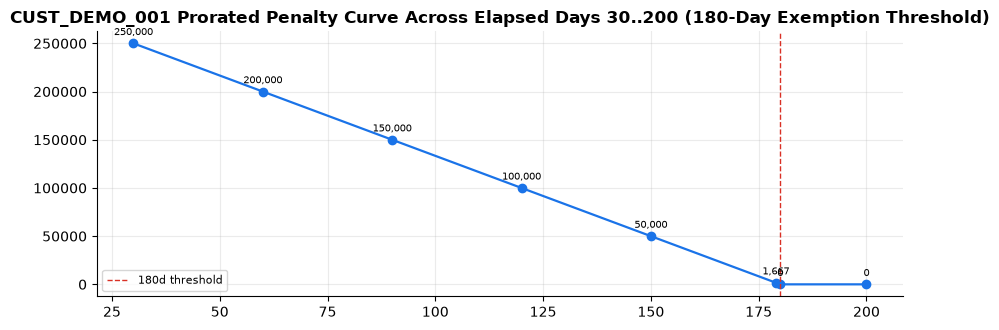

In [4]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       "CUST_DEMO_001 Prorated Penalty Curve Across Elapsed Days 30..200 (180-Day Exemption Threshold)",
       vline=180, vline_label="180d threshold")


### 4. [Phase 7: End-to-End 2-Pass Agent Answering] Golden CQs (`GROUNDED`) & Boundary Guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)


#### CQ-01 (Subsidy & Net Price)
**Q.** When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the public subsidy, retail additional subsidy cap, total subsidy, and net purchase price?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"storage_gb": 256}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 599 | `job_uppNje03tFIr055Xh7dbA4RKMGM9` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"storage_gb": 256}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 5,823 tokens, LLM 22,558 ms / total 23.6 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> 0 matching rows were found in BigQuery (`seanjung-poc.starter_ontology_dw`) for the requested criteria ("AlphaPhone 16 Pro 256GB" on the "5G Signature 115" plan). Consequently, deterministic values for the public subsidy, retail additional subsidy cap, total subsidy, and net purchase price cannot be calculated for these

#### CQ-02 (120d Prorated Penalty)
**Q.** If customer CUST_DEMO_001 downgrades to the 37,000 KRW monthly plan (5G Lite 37) on day 120 after activation, what is the prorated difference penalty?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 501 | `job_AyoAvp8SZrmOf17PcJdXNIHaRFtO` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 520 | `job_myFAIqtL2vi00BQMFwmPQqi6EqdJ` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 969 | `job_mOuccqAG1xnLN7US-XOTv787nXBP`, `job_-fvTl36s4iYusIzK1NtQ80UKtg81` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,407 tokens, LLM 13,824 ms / total 15.82 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> The prorated difference penalty for customer **CUST_DEMO_001** downgrading to the **37,000 KRW** monthly plan (**5G Light (Below Baseline)**) on **day 120** after activation is **100,000 KRW**.
>
> ---
>
> ### Grounded Data (BigQuery)
>
> * **Customer ID**: `CUST_DEMO_001`
> * **Contract ID**: `CONTRACT_DEMO_101`
> * **Contract Type**: `PUBLIC_SUBSIDY`
> * **Welfare Status**: `NONE`
> * **Current Plan**: `5G Premier Essential` (`PLAN-5G-85`)
>   * Current Monthly Fee: **85,000 KRW**
>   * Initial Base Subsidy (`initial_base_subsidy`): **450,000 KRW**
> * **Target Plan**: `5G Light (Below Baseline)` (`PLAN-5G-37`)
>   * Target Monthly Fee: **37,000 KRW**
>   * Target Base Subsidy (`lower_tier_base_subsidy`): **150,000 KRW**
> * **Baseline Threshold**: **45,000 KRW**
> * **Mandatory Retention Period**: **180 days**
> * **Elapsed Days**: **120 days**
>
> #### Penalty Calculation Formula:
> $$\text{Penalty} = \text{ROUND}\left((\text{initial\_base\_subsidy} - \text{lower\_tier\_base\_subsidy}) \times \frac{180 - \text{elapsed\_days}}{180}\right)$$
>
> $$\text{Penalty} = \text{ROUND}\left((450{,}000 - 150{,}000) \times \frac{180 - 120}{180}\right)$$
> $$\text{Penalty} = \text{ROUND}\left(300{,}000 \times \frac{60}{180}\right) = \text{ROUND}(100{,}000) = \mathbf{100{,}000\text{ KRW}}$$
>
> ---
>
> ### Applied Rules & Source Chunks
>
> * **`RULE_SIX_PLAN_180D`** (180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule)
>   * **Chunk ID**: `DOC_CHUNK_003` (also referenced in `DOC_CHUNK_002`)
>   * **Anchor**: `anchor_47971ec8e4d8` (and `anchor_3003b683cea0`)
>   * **Rule Condition**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>
> ---
>
> ### Execution Telemetry
> * **BigQuery Job IDs**:
>   * `job_AyoAvp8SZrmOf17PcJdXNIHaRFtO`
>   * `job_myFAIqtL2vi00BQMFwmPQqi6EqdJ`
>   * `job_mOuccqAG1xnLN7US-XOTv787nXBP`
>   * `job_-fvTl36s4iYusIzK1NtQ80UKtg81`

#### CQ-03 (Welfare Exemption)
**Q.** Is customer CUST_DEMO_002 (registered under National Merit Welfare) exempt from penalty charges when downgrading to a lower plan on day 95?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "lower plan"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 510 | `job_BfNRvD86tdF6RkrxioNxRiR7K8Ji` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 492 | `job_L-x2QGQitydF083Wqfj2v11gnjXA` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 949 | `job_mWlscLY5s00yEv41KO406Qxayw66`, `job_QuUOZjhrHrINJ04i5G04HfKbczMA` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "lower plan"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_002'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,867 tokens, LLM 16,681 ms / total 18.64 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> Customer **CUST_DEMO_002** is **not exempt** from penalty charges under welfare provisions. 
>
> According to customer records in BigQuery, the registered `welfare_status` for CUST_DEMO_002 is **`NONE`**, not National Merit Welfare. Furthermore, welfare penalty exemption under rule `RULE_WELFARE_EXEMPT` strictly applies only when `welfare_status` is in `('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`. 
>
> At day 95 (which is within the mandatory 180-day baseline retention period), downgrading to a plan below the baseline threshold of 45,000 KRW/month triggers a prorated clawback penalty under `RULE_SIX_PLAN_180D`. Because a specific target plan was not designated, the exact penalty amount cannot be resolved (`TARGET_PLAN_NOT_RESOLVED`).
>
> ---
>
> ### Grounded Data (BigQuery)
>
> - **Customer ID**: CUST_DEMO_002
> - **Contract ID**: CONTRACT_DEMO_102
> - **Welfare Status**: NONE
> - **Customer Segment**: General_Standard
> - **Age Group**: 30s-40s
> - **Contract Type**: PUBLIC_SUBSIDY
> - **Current Device**: Galaxy S26 Ultra 256GB (Device ID: `DEV-S26U-256`, Factory Price: 1,698,400 KRW)
> - **Current Plan**: 5G Premier Super (Plan ID: `PLAN-5G-130`, Monthly Fee: 130,000 KRW)
> - **Base Subsidy Received**: 500,000 KRW
> - **Additional Subsidy Received**: 75,000 KRW
> - **Total Subsidy Received**: 575,000 KRW
> - **Mandatory Retention Period**: 180 days
> - **Elapsed Days Evaluated**: 95 days
> - **Baseline Retention Fee Threshold**: 45,000 KRW/month
> - **Penalty Status**: TARGET_PLAN_NOT_RESOLVED (penalty KRW: null)
>
> ---
>
> ### Applied Rules & Source Chunks
>
> 1. **RULE_WELFARE_EXEMPT**: *Senior/Welfare Plan Transition & Military Suspension Penalty Exemption Rule*
>    - **Condition**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>    - **Formula**: `penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE)`
>    - **Determination**: CUST_DEMO_002 has `welfare_status = 'NONE'`, failing the condition for exemption.
>    - **Source Chunk**: `DOC_CHUNK_004` (Anchor: `anchor_269d9c42e05c`)
>
> 2. **RULE_SIX_PLAN_180D**: *180-Day Baseline (45,000 KRW) Mandatory Retention & Prorated Penalty Rule*
>    - **Condition**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>    - **Formula**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>    - **Determination**: At 95 days, downgrading below 45,000 KRW/month incurs a prorated clawback on the subsidy difference over the remaining 85 days (`(180 - 95) / 180`).
>    - **Source Chunk**: `DOC_CHUNK_002` (Anchor: `anchor_3003b683cea0`) / `DOC_CHUNK_003` (Anchor: `anchor_47971ec8e4d8`)
>
> 3. **RULE_SUBSIDY_CAP**: *Public Subsidy & Retail Additional Subsidy Cap (15%) Rule*
>    - **Formula**: `total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory_price_krw - total_subsidy`
>    - **Source Chunk**: `DOC_CHUNK_001` (Anchor: `anchor_a52e1a72869f`)
>
> 4. **RULE_TCO_24M**: *24-Month Public Subsidy vs. 25% Selective Contract TCO Comparison Rule*
>    - **Formula**:
>      - Public Subsidy Path: `(1,698,400 - 575,000) + (130,000 * 24) = 4,243,400 KRW`
>      - Selective Discount Path: `1,698,400 + (130,000 * 0.75 * 24) = 4,038,400 KRW`
>    - **Recommendation**: SELECTIVE_25PCT (Savings: 205,000 KRW)
>    - **Source Chunk**: `DOC_CHUNK_005` (Anchor: `anchor_4fbaf9c5cba8`)
>
> ---
>
> ### Execution Telemetry
>
> - **Customer Profile Lookup**: `job_BfNRvD86tdF6RkrxioNxRiR7K8Ji`
> - **Graph & Wiki Traversal**: `job_L-x2QGQitydF083Wqfj2v11gnjXA`
> - **Penalty & Rule Calculations**: `job_mWlscLY5s00yEv41KO406Qxayw66`, `job_QuUOZjhrHrINJ04i5G04HfKbczMA`

#### BC-PARAM (Missing Customer/Device)
**Q.** I am a newly activated subscriber—what is the penalty if I downgrade to the 5G Lite 37 plan right now?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 545 | `job_lurSure1_ryqK-9Dm_t5WDKZGI-l` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,121 tokens, LLM 20,658 ms / total 21.2 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
> A downgrade to the **5G Light (Below Baseline)** plan (37,000 KRW/month) triggers a subsidy difference clawback penalty if performed within the mandatory **180-day commitment period**, because the plan falls below the 5G baseline threshold of **45,000 KRW/month**. 
>
> The exact penalty is computed deterministically using the formula:
> $$\text{Penalty} = (\text{Initial Granted Subsidy} - \text{Lower Tier Subsidy}) \times \frac{180 - \text{Elapsed Days}}{180}$$
>
> Because your exact device model, initial plan tier, and elapsed days were not specified in the input parameters, the final settlement depends on the initial subsidy granted at activation. For instance, on a newly activated (**Elapsed Days = 0**) **Galaxy S26 Ultra 256GB** downgrading to **5G Light (Below Baseline)** (subsidy: 172,500 KRW):
> - Downgrading from **5G Premier Super** (initial subsidy: 575,000 KRW): **402,500 KRW**
> - Downgrading from **5G Premier Essential** (initial subsidy: 517,500 KRW): **345,000 KRW**
> - Downgrading from **5G Slim (Baseline Threshold)** (initial subsidy: 345,000 KRW): **172,500 KRW**
>
> If **Elapsed Days $\ge$ 180**, the penalty is **0 KRW**.
>
> ---
>
> ### Grounded Data (BigQuery)
>
> #### Device & Plan Policy Catalog (`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)
>
> | Device Name | Plan Name | Monthly Fee (KRW) | Policy ID | Subsidy (KRW) | Factory Price (KRW)

#### BC-NOTFOUND (Unknown Entity)
**Q.** Please calculate the penalty when customer CUST_NOT_EXIST_999 changes plans with a QuantumFold 99 device.

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"device_mention": "QuantumFold 99"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 7 | 1,355 | `job_yfRaXWYf2spUUJ7t23yqLZ9xcP9O` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 536 | `job_S8D7PJf6bnubSsih4g1BAdtXhSEm` |
| 3 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 478 | `job_a-PrPatJ19q2ih4eDtEOPRWAOjYN` |

- **`mcp_query_graph_and_wiki` Executed GQL & Bound Variables** (`params={"device_mention": "QuantumFold 99"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 9,034 tokens, LLM 19,885 ms / total 22.26 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### Conclusion
>
> The penalty calculation cannot be completed due to status `INSUFFICIENT_PARAMETERS`. Customer `CUST_NOT_EXIST_999` and device `QuantumFold 99` do not exist in BigQuery (`seanjung-poc.starter_ontology_dw`). 
>
> To calculate the exact penalty, the following parameters (`missing_slots`) are required:

,id,answer_status,tools,bq_jobs,tokens,llm_ms,bq_ms,total_s
0,CQ-01,GROUNDED,query_graph_and_wiki,2,5823,22558,599,23.60
1,CQ-02,GROUNDED,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,5,6407,13824,1989,15.82
2,CQ-03,GROUNDED,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,5,6867,16681,1951,18.64
3,BC-PARAM,GROUNDED,query_graph_and_wiki,2,6121,20658,545,21.20
4,BC-NOTFOUND,INSUFFICIENT_PARAMETERS,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,4,9034,19885,2369,22.26


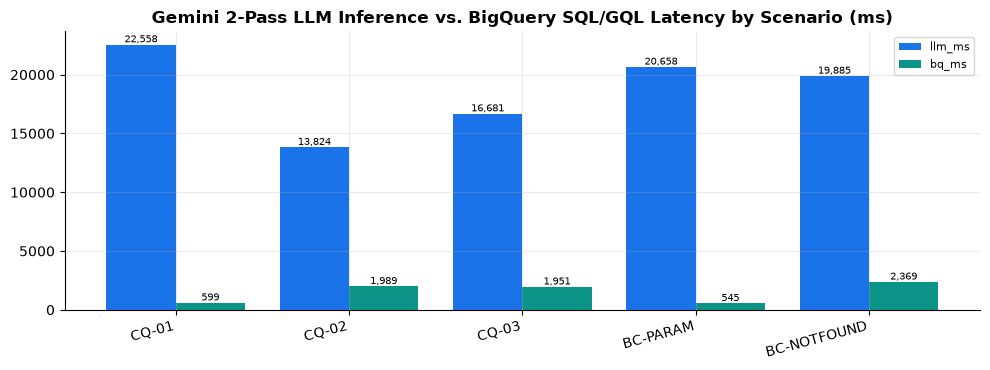

In [5]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "When activating the AlphaPhone 16 Pro 256GB on the 5G Signature 115 plan, what are the public subsidy, retail additional subsidy cap, total subsidy, and net purchase price?"),
    ("CQ-02 (120d Prorated Penalty)", "If customer CUST_DEMO_001 downgrades to the 37,000 KRW monthly plan (5G Lite 37) on day 120 after activation, what is the prorated difference penalty?"),
    ("CQ-03 (Welfare Exemption)", "Is customer CUST_DEMO_002 (registered under National Merit Welfare) exempt from penalty charges when downgrading to a lower plan on day 95?"),
    ("BC-PARAM (Missing Customer/Device)", "I am a newly activated subscriber—what is the penalty if I downgrade to the 5G Lite 37 plan right now?"),
    ("BC-NOTFOUND (Unknown Entity)", "Please calculate the penalty when customer CUST_NOT_EXIST_999 changes plans with a QuantumFold 99 device."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append(H.agent_row(res, qid.split()[0]))
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              "Gemini 2-Pass LLM Inference vs. BigQuery SQL/GQL Latency by Scenario (ms)")


### Q&A
- **Q.** How does the AI FDE Agent prevent penalty calculation errors and hallucinated devices or customers?
  - **A.** `resolve_params()` validates extracted slots against the live BigQuery catalog (`get_live_catalog()`), delegates all arithmetic to deterministic BigQuery SQL inside `mcp_calculate_penalty_rule`, and enforces explicit `INSUFFICIENT_PARAMETERS` and `MATCH_NOT_FOUND` guardrail states.

### Data Analysis Key Findings
- Across elapsed days 30..200 for `CUST_DEMO_001`, the prorated penalty decreases linearly from `250,000 KRW` (day 30) to `100,000 KRW` (day 120) and `1,667 KRW` (day 179), dropping to `0 KRW` (`EXEMPT_RETENTION_COMPLETED`) at day 180.
- All Golden CQs (`CQ-01`–`CQ-03`) returned `GROUNDED` responses citing exact SQL-computed figures (`575,000 KRW`, `100,000 KRW`, `0 KRW`), SHA-256 chunk anchors, and BigQuery Job IDs.
- Missing-slot queries (`BC-PARAM`) triggered `INSUFFICIENT_PARAMETERS` and unknown-entity queries (`BC-NOTFOUND`) triggered `MATCH_NOT_FOUND` with 0 hallucinated figures.

### Insights or Next Steps
- Proceed to the final `Stage 5 (Verify & Evaluate)` notebook to inspect the 4-Tier end-to-end data lineage graph, Golden CQ re-verification, and the 50-trial boundary benchmark release gate.

---
> **Next Navigation**: [⬅️ Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb) ｜ [🌐 Korean Version](../ko/stage4_agent_and_mcp_execution_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/04_stage4_agent_and_mcp_en.md)
